# C_02 Logistic Regression and Agent Ablation

**Owner:** C

## Purpose
1. Train and tune logistic regression as the interpretable predictive baseline.
2. Report its validation, random-test and chronological-test results with the shared evaluation template.
3. Describe how the main predictors relate to cancellation risk.
4. Run the agent ablation promised in the proposal: logistic regression with vs without `agent`.

## Protocol (same as all models)
- Data, features and splits: A's v4 data package (24 primary features; `required_car_parking_spaces` excluded as possible leakage).
- Tuning: 5-fold CV on the random training set only, using A's fixed folds (`cv_folds.csv`, reproduced by `ev.get_cv()`).
- Selection metric: mean CV PR-AUC (threshold-independent, suited to the 37% positive class).
- Final results: `ev.run_standard_experiment()` (validation, random test, chronological test; threshold 0.5).
- PR-AUC denotes average precision, not trapezoidal integration. The OOF summary is post-selection, not nested CV.
- The shared chronological refit uses random-training-selected parameters. Because 17,707 later-test rows
  also occur in random training, its labels informed parameter selection; it is not an untouched future holdout.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.append(str(project_root / "src"))

import evaluation as ev

# Retain version and convergence warnings so that environment issues remain visible.
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

data = ev.load_shared_data(project_root)
X_train = data["random_train"][data["features"]]
y_train = data["random_train"]["is_canceled"]
print("Training rows:", len(X_train), "| input features:", len(data["features"]))

Training rows: 94851 | input features: 24


## 1. Hyperparameter tuning (training set only)

Grid:
- `C` (inverse regularisation strength): 0.001, 0.01, 0.1, 1, 10, 100
- `class_weight`: None or "balanced"

L2 penalty with the lbfgs solver. Several features are derived from others (e.g. `total_nights`,
`total_guests`, `lead_time_group`), and L2 regularisation keeps the coefficients stable under this overlap.
**Selection rule (fixed before looking at test data): one-standard-error rule.** Find the best mean CV
PR-AUC, then choose the most regularised setting (smallest `C`) whose mean CV PR-AUC is within one
standard error of the best. This avoids picking a nearly unregularised model for a gain smaller than
fold-to-fold noise. The other metrics are recorded for reference.

In [2]:
param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
}

lr_pipe = ev.make_pipeline(data, LogisticRegression(max_iter=5000, random_state=ev.SEED))
search = GridSearchCV(lr_pipe, param_grid, cv=ev.get_cv(), scoring=scoring,
                      refit="pr_auc", n_jobs=-1)
search.fit(X_train, y_train)

cv_table = pd.DataFrame(search.cv_results_)
cv_table = pd.DataFrame({
    "C": cv_table["param_model__C"],
    "class_weight": cv_table["param_model__class_weight"].fillna("None"),
    "cv_pr_auc": cv_table["mean_test_pr_auc"],
    "cv_pr_auc_sd": cv_table["std_test_pr_auc"],
    "cv_roc_auc": cv_table["mean_test_roc_auc"],
    "cv_f1": cv_table["mean_test_f1"],
    "cv_recall": cv_table["mean_test_recall"],
    "cv_precision": cv_table["mean_test_precision"],
}).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)

tuning_dir = project_root / "results" / "tuning"
tuning_dir.mkdir(parents=True, exist_ok=True)
cv_table.to_csv(tuning_dir / "logistic_regression_cv_results.csv", index=False)

# One-standard-error rule
best = cv_table.iloc[0]
one_se = best["cv_pr_auc_sd"] / np.sqrt(ev.N_FOLDS)
eligible = cv_table[cv_table["cv_pr_auc"] >= best["cv_pr_auc"] - one_se]
chosen = eligible.sort_values("C").iloc[0]
best_params = {"C": float(chosen["C"]),
               "class_weight": None if chosen["class_weight"] == "None" else chosen["class_weight"]}

display(cv_table.round(4))
print(f"\nHighest mean CV PR-AUC: {best['cv_pr_auc']:.4f} (C={best['C']}, class_weight={best['class_weight']})")
print(f"One standard error: {one_se:.4f}  ->  eligible if CV PR-AUC >= {best['cv_pr_auc'] - one_se:.4f}")
print("Selected settings:", best_params, f"| CV PR-AUC = {chosen['cv_pr_auc']:.4f}")

          C class_weight  cv_pr_auc  cv_pr_auc_sd  cv_roc_auc   cv_f1  cv_recall  cv_precision
0   100.000         None     0.7967        0.0027      0.8652  0.6920     0.6466        0.7444
1    10.000         None     0.7967        0.0027      0.8652  0.6913     0.6457        0.7439
2     1.000         None     0.7966        0.0028      0.8652  0.6915     0.6452        0.7450
3     0.100         None     0.7953        0.0029      0.8648  0.6930     0.6451        0.7486
4    10.000     balanced     0.7910        0.0030      0.8655  0.7258     0.7967        0.6665
5   100.000     balanced     0.7910        0.0029      0.8655  0.7260     0.7969        0.6667
6     1.000     balanced     0.7909        0.0030      0.8655  0.7259     0.7968        0.6666
7     0.100     balanced     0.7888        0.0033      0.8650  0.7252     0.7967        0.6655
8     0.010         None     0.7877        0.0032      0.8599  0.6840     0.6283        0.7506
9     0.010     balanced     0.7821        0.0033 

**Reading the grid.** Performance rises up to about C = 1 and is flat afterwards (differences smaller than
the fold-to-fold variation), so the one-standard-error rule selects C = 1. `class_weight="balanced"` gives higher recall and F1 at the 0.5
threshold but slightly *lower* PR-AUC: it changes the fitted model and its precision-recall trade-off. This is not
mathematically equivalent to changing only the decision threshold. Threshold choice is analysed separately (E), so the
selection uses the threshold-independent PR-AUC and keeps unweighted classes.

## 2. Final logistic regression with the standard protocol

In [3]:
final_lr = ev.make_pipeline(
    data, LogisticRegression(max_iter=5000, random_state=ev.SEED, **best_params)
)
lr_metrics, lr_preds = ev.run_standard_experiment(
    final_lr, model="logistic_regression", data=data, params=best_params, verbose=False
)

dummy_metrics = pd.read_csv(project_root / "results" / "metrics" / "dummy_main_metrics.csv")
show_cols = ["model", "experiment", "subset", "accuracy", "precision", "recall",
             "f1", "roc_auc", "pr_auc", "brier"]
comparison = pd.concat([dummy_metrics, lr_metrics])[show_cols]
display(comparison.sort_values(["experiment", "subset", "model"], ascending=[False, False, True])
        .round(4).reset_index(drop=True))

                 model     experiment      subset  accuracy  precision  recall      f1  roc_auc  pr_auc   brier
0                dummy         random  validation    0.6274     0.0000  0.0000  0.0000   0.5000  0.3726  0.2338
1  logistic_regression         random  validation    0.7855     0.7450  0.6452  0.6915   0.8652  0.7960  0.1431
2                dummy         random        test    0.6274     0.0000  0.0000  0.0000   0.5000  0.3726  0.2338
3  logistic_regression         random        test    0.7873     0.7459  0.6509  0.6952   0.8666  0.8013  0.1420
4                dummy  chronological        test    0.5936     0.0000  0.0000  0.0000   0.5000  0.4064  0.2430
5  logistic_regression  chronological        test    0.7205     0.6339  0.7397  0.6827   0.8019  0.7056  0.1814


In [4]:
# Confusion matrices at threshold 0.5
for _, row in lr_metrics.iterrows():
    print(f"{row['experiment']}-{row['subset']}:  TN={row['tn']:>6}  FP={row['fp']:>5}  "
          f"FN={row['fn']:>5}  TP={row['tp']:>5}")

random-validation:  TN= 51706  FP= 7804  FN=12538  TP=22803
random-test:  TN= 12919  FP= 1959  FN= 3084  TP= 5751
chronological-test:  TN=  9295  FP= 3844  FN= 2342  TP= 6655


## 3. What the model relies on (coefficients)

Coefficients come from the final model fitted on the random training set. Numerical features are
standardised, so their coefficients show the change in log-odds for a one-standard-deviation increase.
All levels of each categorical field are one-hot encoded, with no dropped reference. Under L2
regularisation, an individual category coefficient does not represent a comparison with a specified
reference category. Holding the other inputs fixed, the conditional odds ratio between two levels
of the same field is `exp(coef_level_a - coef_level_b)`; derived and overlapping inputs require care.

Caution: the features overlap (e.g. `lead_time` and `lead_time_group`; `total_nights` and its two
components), so individual coefficients inside such a group should be read together, not one by one.
All statements describe association with predicted risk, not causes of cancellation.

In [5]:
pkg = joblib.load(project_root / "results" / "models" / "logistic_regression_main.joblib")
coef = pkg["pipeline"].named_steps["model"].coef_.ravel()
coef_table = pd.DataFrame({
    "feature": [n.split("__", 1)[1] for n in pkg["processed_feature_names"]],
    "coef": coef,
})
coef_table["odds_ratio"] = np.exp(coef_table["coef"])
coef_table = coef_table.sort_values("coef", ascending=False).reset_index(drop=True)
coef_table.to_csv(project_root / "results" / "metrics" / "logistic_regression_coefficients.csv",
                  index=False)

print("Highest-risk associations (top 12):")
display(coef_table.head(12).round(3))
print("\nLowest-risk associations (bottom 12):")
display(coef_table.tail(12).iloc[::-1].reset_index(drop=True).round(3))

Highest-risk associations (top 12):
                   feature   coef  odds_ratio
0                agent_236  3.591      36.272
1              country_AGO  2.392      10.931
2              country_PRT  2.272       9.702
3                agent_326  2.242       9.408
4   previous_cancellations  2.148       8.568
5                 agent_17  2.145       8.541
6                 agent_68  2.121       8.336
7                 agent_31  2.057       7.821
8                agent_170  1.840       6.299
9                agent_240  1.554       4.730
10                agent_41  1.547       4.696
11               agent_134  1.509       4.524

Lowest-risk associations (bottom 12):
                     feature   coef  odds_ratio
0                  agent_220 -2.287       0.102
1                country_SRB -1.800       0.165
2                  agent_168 -1.744       0.175
3                   agent_16 -1.594       0.203
4                   agent_28 -1.552       0.212
5   lead_time_group_0-7 days -1.515    

In [6]:
# Numerical features only (standardised, directly comparable)
num_features = data["preprocessor"].transformers[0][2]
num_coef = coef_table[coef_table["feature"].isin(num_features)].sort_values("coef", ascending=False)
display(num_coef.reset_index(drop=True).round(3))

                           feature   coef  odds_ratio
0           previous_cancellations  2.148       8.568
1                arrival_date_year  0.419       1.521
2                        lead_time  0.358       1.430
3         arrival_date_week_number  0.339       1.403
4                         children  0.076       1.079
5             stays_in_week_nights  0.071       1.073
6                     total_nights  0.065       1.068
7                     total_guests  0.051       1.053
8          stays_in_weekend_nights  0.033       1.033
9                           adults  0.025       1.025
10       arrival_date_day_of_month -0.019       0.981
11                  family_booking -0.073       0.930
12                          babies -0.075       0.928
13               is_repeated_guest -0.172       0.842
14  previous_bookings_not_canceled -0.832       0.435


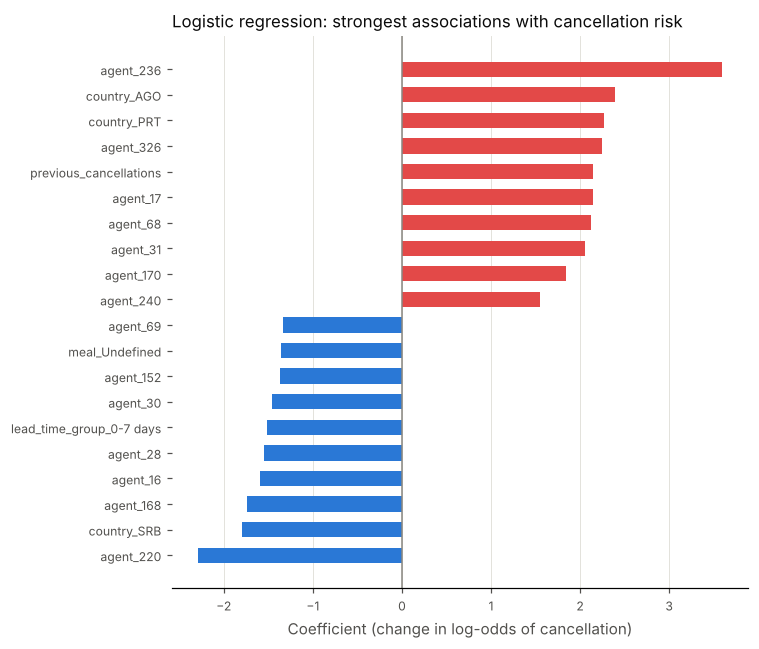

In [7]:
# Figure: the 10 strongest positive and negative coefficients
top = pd.concat([coef_table.head(10), coef_table.tail(10)]).sort_values("coef")
colors = np.where(top["coef"] > 0, "#e34948", "#2a78d6")  # red = higher risk, blue = lower risk

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top["feature"], top["coef"], color=colors, height=0.6)
ax.axvline(0, color="#898781", linewidth=1)
ax.set_xlabel("Coefficient (change in log-odds of cancellation)", color="#52514e")
ax.set_title("Logistic regression: strongest associations with cancellation risk",
             loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.6)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors="#52514e", labelsize=8)
fig.tight_layout()
fig_dir = project_root / "results" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "C_lr_top_coefficients.png", dpi=200, bbox_inches="tight")

## 4. Agent ablation (with vs without `agent`)

`agent` is an identifier-like categorical field, and the proposal asks whether the model depends on it. The comparison keeps
everything else identical: same selected settings, same splits, same folds, same metrics. Only `agent`
is removed from the input features.

In [8]:
no_agent_lr = ev.make_pipeline(
    data, LogisticRegression(max_iter=5000, random_state=ev.SEED, **best_params),
    drop_features=["agent"],
)
na_metrics, na_preds = ev.run_standard_experiment(
    no_agent_lr, model="logistic_regression", variant="no_agent", data=data,
    drop_features=["agent"], params={**best_params, "dropped": ["agent"]}, verbose=False,
)

key = ["experiment", "subset"]
metric_cols = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
ablation = lr_metrics[key + metric_cols].merge(
    na_metrics[key + metric_cols], on=key, suffixes=("_with", "_without"))
for m in metric_cols:
    ablation[f"{m}_change"] = ablation[f"{m}_without"] - ablation[f"{m}_with"]

ablation.to_csv(project_root / "results" / "metrics" / "logistic_regression_agent_ablation.csv",
                index=False)
display(ablation[key + [f"{m}_with" for m in ["f1", "roc_auc", "pr_auc"]]
                 + [f"{m}_without" for m in ["f1", "roc_auc", "pr_auc"]]
                 + [f"{m}_change" for m in ["f1", "roc_auc", "pr_auc"]]].round(4))

      experiment      subset  f1_with  roc_auc_with  pr_auc_with  f1_without  roc_auc_without  pr_auc_without  f1_change  roc_auc_change  pr_auc_change
0         random  validation   0.6915        0.8652       0.7960      0.6829           0.8475          0.7807    -0.0087         -0.0177        -0.0154
1         random        test   0.6952        0.8666       0.8013      0.6858           0.8478          0.7837    -0.0094         -0.0188        -0.0176
2  chronological        test   0.6827        0.8019       0.7056      0.6500           0.7893          0.7048    -0.0327         -0.0125        -0.0008


In [9]:
# Fold-to-fold variation of the validation PR-AUC, to judge whether the difference is meaningful
def fold_pr_auc(preds):
    val = preds[preds["subset"] == "validation"]
    return val.groupby("fold").apply(
        lambda g: ev.compute_metrics(g["y_true"], g["y_prob"])["pr_auc"], include_groups=False)

fold_compare = pd.DataFrame({"with_agent": fold_pr_auc(lr_preds),
                             "without_agent": fold_pr_auc(na_preds)})
fold_compare["change"] = fold_compare["without_agent"] - fold_compare["with_agent"]
display(fold_compare.round(4))
print("Folds where removing agent lowers PR-AUC:", int((fold_compare["change"] < 0).sum()), "of 5")

      with_agent  without_agent  change
fold                                   
1         0.7949         0.7790 -0.0159
2         0.7982         0.7823 -0.0159
3         0.7926         0.7803 -0.0122
4         0.8003         0.7823 -0.0180
5         0.7949         0.7802 -0.0147
Folds where removing agent lowers PR-AUC: 5 of 5


## 5. Files produced

In [10]:
for p in [
    "results/tuning/logistic_regression_cv_results.csv",
    "results/metrics/logistic_regression_main_metrics.csv",
    "results/predictions/logistic_regression_main_predictions.csv",
    "results/models/logistic_regression_main.joblib",
    "results/metrics/logistic_regression_no_agent_metrics.csv",
    "results/predictions/logistic_regression_no_agent_predictions.csv",
    "results/models/logistic_regression_no_agent.joblib",
    "results/metrics/logistic_regression_coefficients.csv",
    "results/metrics/logistic_regression_agent_ablation.csv",
    "results/figures/C_lr_top_coefficients.png",
]:
    print("OK " if (project_root / p).is_file() else "MISSING ", p)

OK  results/tuning/logistic_regression_cv_results.csv
OK  results/metrics/logistic_regression_main_metrics.csv
OK  results/predictions/logistic_regression_main_predictions.csv
OK  results/models/logistic_regression_main.joblib
OK  results/metrics/logistic_regression_no_agent_metrics.csv
OK  results/predictions/logistic_regression_no_agent_predictions.csv
OK  results/models/logistic_regression_no_agent.joblib
OK  results/metrics/logistic_regression_coefficients.csv
OK  results/metrics/logistic_regression_agent_ablation.csv
OK  results/figures/C_lr_top_coefficients.png


## 6. Summary for the report

**Selected model.** L2 logistic regression, `C = 1`, no class weighting (one-standard-error rule on
5-fold CV PR-AUC: 0.7966 vs best 0.7967), trained on A's 24 primary features.

**Performance (threshold 0.5).**

| | Dummy | Logistic regression |
|---|---|---|
| Random test PR-AUC | 0.373 | 0.801 |
| Random test ROC-AUC | 0.500 | 0.867 |
| Random test F1 / recall | 0 / 0 | 0.695 / 0.651 |
| Chronological test PR-AUC | 0.406 | 0.706 |
| Chronological test ROC-AUC | 0.500 | 0.802 |

- Logistic regression is clearly better than the Dummy baseline on every threshold-free and
  threshold-based metric, so the features carry real predictive signal.
- Validation and random-test results are close (AP 0.796 vs 0.801). This does not establish that
  selection did not overfit: parameter selection reuses these validation folds, and identical
  predictor profiles can occur across folds and between random training and test.
- On later arrivals (May–Aug 2017) ranking quality drops (ROC-AUC 0.867 → 0.802, PR-AUC 0.801 → 0.706).
  At the same 0.5 threshold recall rises (0.65 → 0.74) but precision falls (0.75 → 0.63): the model flags
  more bookings as risky in the later period, producing more false alarms. Part of the random-test score
  may also be optimistic because of duplicate feature rows shared between training and test.

**Main associations (direction only, not causes).**
- Higher predicted risk: previous cancellations, longer lead time, bookings from Portugal (PRT), and
  certain travel agents.
- Lower predicted risk: previous non-cancelled bookings, very short lead time (0–7 days), repeat guests,
  and certain travel agents.

**Agent ablation.**
- Random split: removing `agent` lowers PR-AUC by about 0.015–0.018 (validation and test) and lowers it in
  all 5 CV folds, so `agent` adds consistent information when past and future bookings are mixed.
- Chronological test: PR-AUC is essentially unchanged (−0.001) and ROC-AUC falls 0.013, while F1 falls
  0.033 at the 0.5 threshold.
- Interpretation: the incremental AP associated with agent is smaller in the shared chronological
  refit than in the random test. This same-parameter ablation is diagnostic, with no retuning of
  the reduced-feature model. It does not isolate causality or establish why the difference occurs.